Este código permite comparar configuraciones distintas y graficar sus curvas de precisión y pérdida por época:

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt

In [2]:
# Cargar datos
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
# Configuraciones a comparar
configs = {
    "1 capa (128)": [(128, 0.0)],
    "2 capas (128,64)": [(128, 0.0), (64, 0.0)],
    "3 capas (128,64,32)": [(128, 0.0), (64, 0.0), (32, 0.0)],
    "3 capas + dropout": [(128, 0.3), (64, 0.3), (32, 0.3)]
}

histories = {}

In [4]:
for name, config in configs.items():
    print(f"Entrenando: {name}")
    model = Sequential([Flatten(input_shape=(28, 28))])
    for units, dropout in config:
        model.add(Dense(units, activation='relu'))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=10, batch_size=128, verbose=0, validation_data=(x_test, y_test))
    histories[name] = history

Entrenando: 1 capa (128)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Entrenando: 2 capas (128,64)
Entrenando: 3 capas (128,64,32)
Entrenando: 3 capas + dropout


<ipython-input-5-1c40474389cb>:10: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


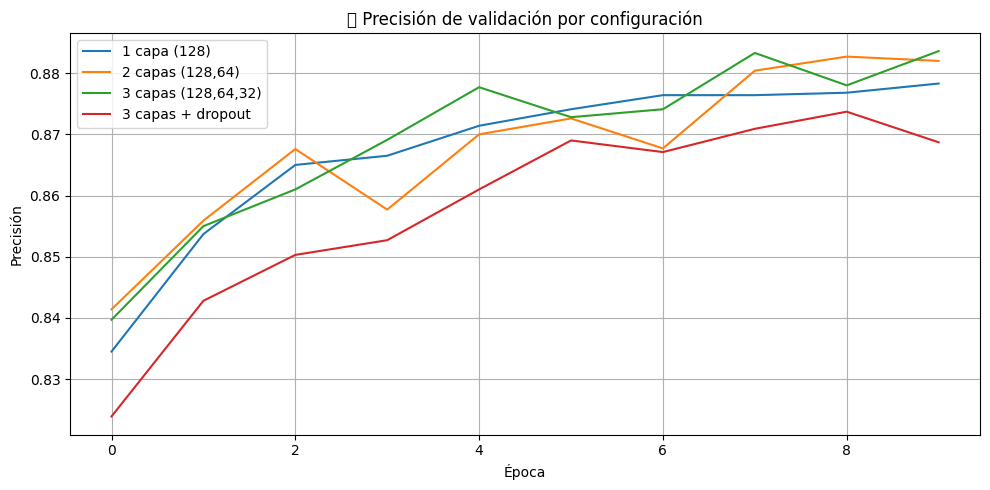

In [5]:
# Graficar precisión
plt.figure(figsize=(10, 5))
for name, hist in histories.items():
    plt.plot(hist.history['val_accuracy'], label=name)
plt.title("📈 Precisión de validación por configuración")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

<ipython-input-6-3065d4e9c3a9>:10: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


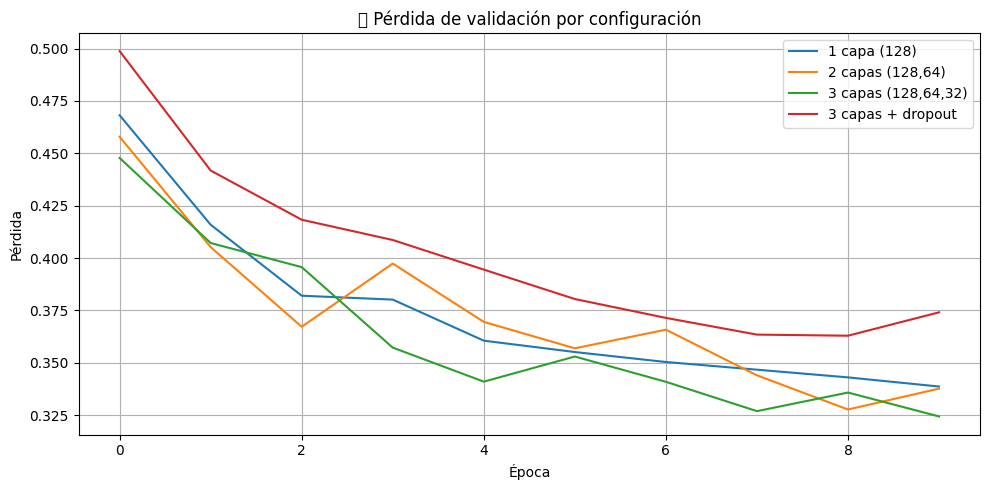

In [6]:
# Graficar pérdida
plt.figure(figsize=(10, 5))
for name, hist in histories.items():
    plt.plot(hist.history['val_loss'], label=name)
plt.title("📉 Pérdida de validación por configuración")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()